# Example of an interface usage - Get the Screen Image

`get_screens(names)` returns, for every screen, the image and what the interface computed from it: the centroid `x`, `y` and the RMS sizes `sigx`, `sigy`, in mm. `hedges` and `vedges` are the pixel edges in mm.

The example uses the tutorial beamline with one screen. With `InterfaceCLEAR_RFTrack()` or `InterfaceCLEAR()` the same code reads CLEAR screens such as `'CA.BTV0620'`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from tutorial_support import Beamline

interface = Beamline()
screen = 'SCREEN1'
print('Screens:', interface.get_screens()['names'])

Screens: ['SCREEN1']


## Read and show the image

Simulated images are stored as `[x, y]`, camera images as `[row = y, column = x]`. The check in `show` puts x on the horizontal axis in both cases, as the Emittance Measurement GUI does.

In [ ]:
before = interface.get_screens([screen])
print(f"σx = {before['sigx'][0]:.3f} mm, σy = {before['sigy'][0]:.3f} mm")

In [2]:
def show(ax, data, title):
    image, h, v = data['images'][0], data['hedges'][0], data['vedges'][0]
    if image.shape == (h.size - 1, v.size - 1):
        image = image.T
    ax.imshow(image, origin='lower', extent=[h[0], h[-1], v[0], v[-1]], aspect='auto')
    ax.set(xlabel='x [mm]', ylabel='y [mm]', title=f"{title}: x = {data['x'][0]:.2f} mm, y = {data['y'][0]:.2f} mm")

σx = 0.499 mm, σy = 0.301 mm


## Move the beam with correctors

Remember the settings, change them inside `try` and restore them in `finally`. `set_correctors` takes absolute values and returns `False` when a readback does not reach the request.

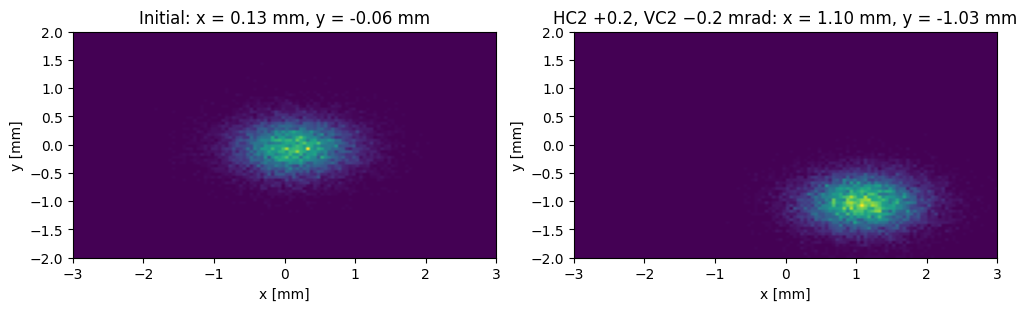

In [3]:
correctors = ['HC2', 'VC2']
initial = interface.get_correctors(correctors)['bdes']
try:
    if interface.set_correctors(correctors, initial + np.array([0.2, -0.2])) is False:
        raise RuntimeError('Correctors did not reach the requested values')
    after = interface.get_screens([screen])
finally:
    interface.set_correctors(correctors, initial)

fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
show(axes[0], before, 'Initial')
show(axes[1], after, 'HC2 +0.2, VC2 −0.2 mrad')
plt.show()